# Phase 3 (Gemini): shallow KiL (policy graph as text in the prompt)

**Goal:** a KiL arm for RQ1/RQ2 and H1. Same agent, model, settings and prose prompt as 05G; the only change is how the policy graph reaches the agent.

**How it works:** the whole policy graph is turned into plain text rules (`graph_text.py`) and added to the agent's system prompt, after the prose `wiki.md`. Nothing else changes: no validator, no extra calls. The user simulator does not see it.

**Why "after the prose" and not "instead of":** the graph has the same rules as `wiki.md` but not every sentence (e.g. how the database is laid out). Keeping the prose means the agent loses nothing; the arm tests whether *adding the structured form* helps. The price: the prompt is longer (about 1,100 more words), so the rules appear twice. Any gain could partly come from this repetition; in the end pass^k did not change, so repetition did not help either.

**Run first:** 05G (writes `settings_gemini.py`, `gemini_run.py`), 06G (writes `policy_checker.py`, `violations.py`), 04 (the graph). This notebook writes `graph_text.py` and `kil_run.py`.

**Runtime:** CPU only. **Model:** whatever `settings_gemini.py` says (now `gemini-3.1-flash-lite`, paid Gemini API).

**Run:** 50 tasks × 8 trials into `results_gemini_shallow/trial_1..8/`. Safe to stop: finished tasks are skipped. If the credits run out, the run stops; add credits and run the cell again.

**Compared with:** the baseline (05G) and the validator (06G), on all 50 tasks and on the 42 clean tasks (the 8 label-conflict tasks are 10, 16, 19, 26, 27, 34, 45, 46).

**Result (done):** pass^1 0.520, pass^8 0.340, same as the baseline; violations 70 → 31. See the Summary at the end.

In [ ]:
# mount Google Drive so results are saved
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# go into the repo and install tau-bench (CPU runtime)
%cd /content/drive/MyDrive/cmsc691-10-project2
!pip install -q -e .
!pip install -q mcp
print("installed")

/content/drive/MyDrive/cmsc691-10-project2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau_bench (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-dataproc 5.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires 

In [ ]:
# load settings, connect to Gemini (API key or Colab), and check tool calling once
import os, sys, re, importlib, logging, warnings
import pandas as pd
from IPython.display import display
sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-project2")
os.chdir("/content/drive/MyDrive/cmsc691-10-project2")
for f in ["settings_gemini.py", "gemini_run.py", "policy_checker.py", "violations.py",
          "airline_policy_graph.json", "passk.py"]:
    assert os.path.exists(f), f"{f} missing: run 05G, 06G and 04 first"
importlib.invalidate_caches()
import settings_gemini; importlib.reload(settings_gemini)
from settings_gemini import *
warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)   # hide litellm's long warnings

def short_error(e):
    # keep only the API's own message, one line
    m = re.search(r'"message":\s*"([^"]+)"', str(e))
    return (m.group(1) if m else str(e).splitlines()[0])[:200]

def set_token():
    if BACKEND == "colab":
        # the Colab token can expire, so I get a fresh one before each run
        from google.colab import ai
        os.environ["COLAB_PROXY_BASE"] = f"{ai._get_model_proxy_host()}/models/openapi"
        os.environ["COLAB_PROXY_KEY"] = ai._get_model_proxy_token()
    else:
        # my key from Colab Secrets (name GEMINI_API_KEY); never printed
        from google.colab import userdata
        os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
set_token()

display(pd.DataFrame({"setting": [k for k in vars(settings_gemini) if k.isupper()],
                       "value": [vars(settings_gemini)[k] for k in vars(settings_gemini) if k.isupper()]})
        .set_index("setting").T)

import litellm
litellm.suppress_debug_info = True
tools = [{"type": "function", "function": {
    "name": "get_reservation", "description": "Look up a reservation",
    "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}},
                   "required": ["reservation_id"]}}}]
if BACKEND == "colab":
    kw = dict(model=PROXY_PREFIX + MODEL, custom_llm_provider="openai",
              api_base=os.environ["COLAB_PROXY_BASE"], api_key=os.environ["COLAB_PROXY_KEY"])
else:
    kw = dict(model=MODEL, custom_llm_provider="gemini", api_key=os.environ["GEMINI_API_KEY"])
try:
    r = litellm.completion(**kw, temperature=0.0, tools=tools,
                           messages=[{"role": "user", "content": "Look up reservation ABC123."}])
    ok = bool(r.choices[0].message.tool_calls)
    print(f"{'✅ tool call works' if ok else '❌ no tool call'} | model {MODEL}")
except Exception as e:
    print(f"❌ {type(e).__name__}: {short_error(e)}")
    print("Fix MODEL in settings_gemini.py (05G, cell 3), run that cell in 05G, then this cell again.")

setting,BACKEND,MODEL,PRICE_IN,PRICE_OUT,PROXY_PREFIX,TEMPERATURE,USER_TEMPERATURE,CONCURRENCY,NUM_RETRIES,CALL_TIMEOUT,ENV,N_TASKS,N_TRIALS
value,apikey,gemini-3.1-flash-lite,0.25,1.5,google/,0.0,1.0,4,6,600,airline,50,8


✅ tool call works | model gemini-3.1-flash-lite


In [ ]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/graph_text.py
# Turn the policy graph (airline_policy_graph.json) into plain text rules.
# 07 shallow puts the whole text in the system prompt.
# 08 semi-deep puts only the part for one action in front of the agent, right before it acts.
# Same content as the graph: nothing added, nothing dropped.
import json
import os

_HERE = os.path.dirname(os.path.abspath(__file__))
GRAPH_PATH = os.environ.get("POLICY_GRAPH", os.path.join(_HERE, "airline_policy_graph.json"))
ROMAN = ["i", "ii", "iii", "iv", "v", "vi"]
LETTERS = "abcdefgh"


def load(path=GRAPH_PATH):
    return json.load(open(path))


def _where(c):
    # where the agent can see whether the rule holds
    if c.get("check") == "data":
        return "check in the tool results"
    return "check in the conversation" if c.get("actor") == "user" else "your own behaviour"


def _if_fails(c):
    f = c.get("if_fails")
    if f == "transfer_to_human_agents":
        return " If not: transfer the user to a human agent."
    if f == "deny":
        return " If not: deny the request (G4)."
    return ""


def _cond(c, depth=0):
    """Lines for one condition, with OR / AND groups indented."""
    pad = "   " * (depth + 1)
    out = []
    if "any_of" in c or "all_of" in c:
        kind, subs = ("ANY ONE of", c["any_of"]) if "any_of" in c else ("ALL of", c["all_of"])
        extra = f" (amount: {c['amount']})" if "amount" in c else ""
        out.append(f"{kind}:{extra}{_if_fails(c)}")
        marks = LETTERS if depth == 0 else ROMAN
        for j, s in enumerate(subs):
            sub = _cond(s, depth + 1)
            out.append(f"{pad}{marks[j]}. {sub[0]}")
            out += sub[1:]
        return out
    txt = f"{c['condition']} [{c['source']}; {_where(c)}]"
    if "must_happen_before" in c:
        txt += f" (must be done before {c['must_happen_before']})"
    if "amount" in c:
        txt += f" (amount: {c['amount']})"
    return [txt + _if_fails(c)]


def action_text(g, name):
    a = next(x for x in g["actions"] if x["action"] == name)
    lines = [f"### {a['action']} (tool: {a['tool']}; from {', '.join(a['read'])})"]
    if a.get("needs_info"):
        info = "; ".join(f"{i['info']} [{i['source']}]" for i in a["needs_info"])
        lines.append(f"Ask the user first: {info}")
    glob = [r for r in g["global_rules"] if name in r.get("applies_to", [])]
    for r in glob:
        lines.append(f"Before the call: {r['condition']} [{r['source']}]")
    lines.append("Allowed only if ALL of these hold:")
    for k, c in enumerate(a["conditions"], 1):
        sub = _cond(c)
        lines.append(f"  {k}. {sub[0]}")
        lines += ["  " + s for s in sub[1:]]
    for f in a.get("facts", []):
        lines.append(f"Fact: {f['text']} [{f['source']}]")
    for t in a.get("tables", []):
        rows = "; ".join(f"{tier}: " + ", ".join(f"{cab} {n}" for cab, n in r.items())
                         for tier, r in t["rows"].items())
        lines.append(f"Table {t['name']} [{t['source']}] ({t['key']}): {rows}; "
                     f"each extra bag costs ${t['extra_bag_price']}")
    return "\n".join(lines)


def full_text(g):
    lines = ["# Policy checklist (the same rules as the policy above, written as a graph)",
             "", "## Global rules (every conversation)"]
    for r in g["global_rules"]:
        scope = f" Applies to: {', '.join(r['applies_to'])}." if "applies_to" in r else ""
        lines.append(f"- {r['condition']} [{r['source']}].{scope}")
    lines += ["", "## Actions"]
    for a in g["actions"]:
        lines += ["", action_text(g, a["action"])]
    return "\n".join(lines)


if __name__ == "__main__":
    print(full_text(load()))

Writing /content/drive/MyDrive/cmsc691-10-project2/graph_text.py


In [ ]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/kil_run.py
# KiL arms on Gemini. Same agent, model and settings as 05G (gemini_run.py runs them).
# KIL_MODE picks how the policy graph reaches the agent (no validator in either arm):
#   "shallow"  (07): the whole graph, as text rules, is added to the system prompt once.
#   "semideep" (08): the graph is used step by step. When the agent is about to call a
#                    write tool, the rules for that one action are retrieved from the graph
#                    and shown to it; it must check each rule against the conversation and
#                    the tool results, then either repeat the call or not call it.
import json
import os
import runpy
import sys
import threading

import litellm
import graph_text as gt

MODE = os.environ["KIL_MODE"]
assert MODE in ("shallow", "semideep"), MODE
G = gt.load()
WRITE_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
               "update_reservation_passengers", "cancel_reservation", "send_certificate"}
CHECK_LOG = os.environ.get("CHECK_LOG", "kil_checks.jsonl")
_lock = threading.Lock()

if MODE == "shallow":
    # the airline env reads WIKI when it is built, so I extend it before run.main()
    import tau_bench.envs.airline.env as airline_env
    airline_env.WIKI = airline_env.WIKI + "\n\n" + gt.full_text(G)

if MODE == "semideep":
    # one tool can be two graph actions (change flights, or only the cabin)
    ACTIONS = {"update_reservation_flights": ["update_reservation_flights", "upgrade_cabin"]}

    def rules_for(tool):
        names = ACTIONS.get(tool, [tool])
        head = ("whichever of these fits the call" if len(names) > 1 else "")
        return (head + "\n\n" if head else "") + "\n\n".join(gt.action_text(G, n) for n in names)

    def check_prompt(call):
        name = call.function.name
        return (
            f"[Policy check before acting] You are about to call {name} with "
            f"{call.function.arguments}. These are the rules for this action, from the policy graph:\n\n"
            f"{rules_for(name)}\n\n"
            "Go through the rules one by one. For each, say in one short line whether it is met, "
            "not met, or unknown, using only this conversation and the tool results so far. "
            "Then: if every rule is met, make the same tool call again (fix the arguments if needed). "
            "If a rule is not met or unknown, do not call the tool; ask the user or explain the policy.")

    import tau_bench.agents.tool_calling_agent as agent_mod

    def semideep(*args, **kwargs):
        # litellm.completion is looked up at call time, so gemini_run.py's backend
        # and logging (patched later) are used for both calls
        res = litellm.completion(*args, **kwargs)
        msg = res.choices[0].message
        calls = msg.tool_calls or []
        if not calls or calls[0].function.name not in WRITE_TOOLS:
            return res
        first = calls[0]
        kw = dict(kwargs)
        kw["messages"] = list(kwargs["messages"]) + [{"role": "user", "content": check_prompt(first)}]
        res2 = litellm.completion(*args, **kw)
        m2 = res2.choices[0].message
        c2 = (m2.tool_calls or [None])[0]
        row = {"tool": first.function.name,
               "decision": "repeat" if c2 and c2.function.name == first.function.name else
                           ("other_tool" if c2 else "no_call"),
               "args_changed": bool(c2 and c2.function.name == first.function.name
                                    and c2.function.arguments != first.function.arguments)}
        with _lock, open(CHECK_LOG, "a") as f:
            f.write(json.dumps(row) + "\n")
        return res2

    agent_mod.completion = semideep

# same agent, model and backend as 05G
here = os.path.dirname(os.path.abspath(__file__))
runpy.run_path(os.path.join(here, "gemini_run.py"), run_name="__main__")

Writing /content/drive/MyDrive/cmsc691-10-project2/kil_run.py


In [ ]:
# what the agent gets: the prose policy + this checklist (rendered from the graph)
import importlib, graph_text as gt; importlib.reload(gt)
text = gt.full_text(gt.load())
print(f"checklist: {len(text.split())} words, added after wiki.md\n")
print(text[:2500], "\n...")

checklist: 1107 words, added after wiki.md

# Policy checklist (the same rules as the policy above, written as a graph)

## Global rules (every conversation)
- list the action details and get an explicit 'yes' from the user before the action [G1]. Applies to: book_reservation, update_reservation_flights, update_reservation_baggages, upgrade_cabin, update_reservation_passengers.
- give no information, knowledge or procedures not given by the user or the tools; no subjective recommendations or comments [G2].
- make one tool call at a time; never call a tool and reply to the user in the same turn [G3].
- deny user requests that are against this policy [G4].
- transfer to a human agent if and only if the request cannot be handled by any of the agent's actions [G5].

## Actions

### book_reservation (tool: book_reservation; from B1, B2, B3, B4, B5, D3)
Ask the user first: user_id [B1]; trip_type (one way or round trip) [B1]; origin [B1]; destination [B1]; first name, last name, date of birt

In [ ]:
# run the Shallow KiL arm: 8 trials, one folder each, skip what is done
import os, sys, time, json, importlib
import passk; importlib.reload(passk)
%cd /content/drive/MyDrive/cmsc691-10-project2
OUT = "results_gemini_shallow"
LOGS = "/content/drive/MyDrive/cmsc691-10-project2/logs_gemini"
os.makedirs(LOGS, exist_ok=True)
os.environ["KIL_MODE"] = "shallow"
json.dump({**{k: v for k, v in vars(settings_gemini).items() if k.isupper()},
           "policy": "prose wiki.md + policy graph (shallow)", "kil_mode": "shallow",
           "backend": "Colab built-in Gemini" if BACKEND == "colab" else "paid Gemini API (AI Studio key)"},
          open(f"{OUT}_config.json", "w"), indent=2)
start_all = time.time()
for trial in range(1, N_TRIALS + 1):
    folder = f"{OUT}/trial_{trial}"
    os.makedirs(folder, exist_ok=True)
    todo = sorted(set(range(N_TASKS)) - passk.done_tasks(folder))
    if not todo:
        print(f"trial {trial}: done, skip")
        continue
    print(f"trial {trial}: running {len(todo)} tasks ...", end=" ", flush=True)
    t0 = time.time()
    ids = " ".join(map(str, todo))
    set_token()
    os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
    os.environ["CHECK_LOG"] = f"{folder}/checks.jsonl"
    log = f"{LOGS}/shallow_trial_{trial}.log"
    !echo "===== run at $(date) =====" >> {log}
    !python kil_run.py --env {ENV} --agent-strategy tool-calling \
      --model {MODEL} --model-provider openai \
      --user-model {MODEL} --user-model-provider openai \
      --user-strategy llm --num-trials 1 --temperature {TEMPERATURE} \
      --task-ids {ids} --max-concurrency {CONCURRENCY} \
      --log-dir {folder} >> {log} 2>&1
    left = N_TASKS - len(passk.done_tasks(folder))
    print(f"{(time.time() - t0) / 60:.1f} min, {left} not done")
print(f"\nall trials: {(time.time() - start_all) / 60:.1f} min this session")

/content/drive/MyDrive/cmsc691-10-project2
trial 1: running 50 tasks ... 63.7 min, 0 not done
trial 2: running 50 tasks ... 35.6 min, 0 not done
trial 3: running 50 tasks ... 52.1 min, 0 not done
trial 4: running 50 tasks ... 4.9 min, 0 not done
trial 5: running 50 tasks ... 43.5 min, 0 not done
trial 6: running 50 tasks ... 6.7 min, 0 not done
trial 7: running 50 tasks ... 43.8 min, 0 not done
trial 8: running 50 tasks ... 55.0 min, 0 not done

all trials: 305.4 min this session


In [ ]:
# progress: tasks done and API errors per trial, as a table
import pandas as pd, importlib, passk; importlib.reload(passk)
from collections import Counter
from IPython.display import display
tab = passk.table("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_shallow")
prog = []
for trial in range(1, N_TRIALS + 1):
    rows = tab.get(trial, {})
    prog.append({"trial": trial, "done": f"{len(rows)}/{N_TASKS}",
                 "passed": sum(r["reward"] >= 1 - 1e-6 for r in rows.values()),
                 "API errors": sum(passk.is_error(r) for r in rows.values())})
display(pd.DataFrame(prog).set_index("trial").T)
kinds = Counter(short_error(r["info"]["error"]) for t in tab.values() for r in t.values() if passk.is_error(r))
for msg, c in kinds.most_common(3):
    print(f"{c} x {msg}")

trial,1,2,3,4,5,6,7,8
done,50/50,50/50,50/50,50/50,50/50,50/50,50/50,50/50
passed,28,27,24,26,27,27,25,24
API errors,0,0,0,0,0,0,0,0


baseline: complete trials 8
validator: complete trials 8
shallow kil: complete trials 8


k,1,2,3,4,5,6,7,8
baseline,0.525,0.443,0.406,0.386,0.376,0.370,0.365,0.36
validator,0.573,0.501,0.460,0.432,0.412,0.398,0.388,0.38
shallow kil,0.520,0.432,0.392,0.369,0.355,0.347,0.343,0.34


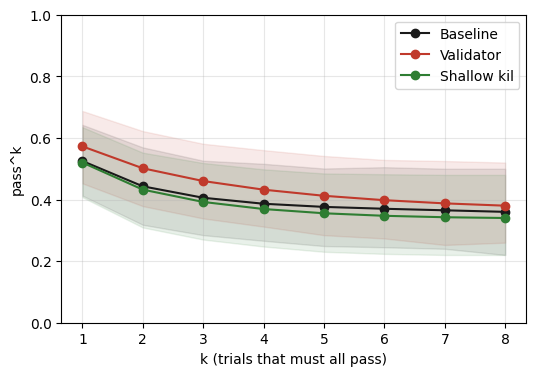

In [ ]:
# pass^k curves with 95% CI: baseline, validator, Shallow KiL
import os, csv
import pandas as pd
import matplotlib.pyplot as plt
import importlib, passk; importlib.reload(passk)
from IPython.display import display
ARMS = [("baseline", "results_gemini_baseline", "#1A1A1A"),
        ("validator", "results_gemini_validator", "#C0392B"),
        ("shallow kil", "results_gemini_shallow", "#2E7D32")]
curves = {}
for name, d, _ in ARMS:
    n, rows = passk.curve(f"/content/drive/MyDrive/cmsc691-10-project2/{d}", N_TASKS)
    curves[name] = rows
    print(f"{name}: complete trials {n}")
tab = pd.DataFrame({name: [round(r["pass^k"], 3) for r in rows] for name, rows in curves.items() if rows},
                   index=pd.Index(range(1, 9), name="k")).T
display(tab)
rows = curves["shallow kil"]
if rows:
    with open("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_shallow_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
    plt.figure(figsize=(6, 4))
    for name, _, color in ARMS:
        r = curves[name]
        if not r: continue
        ks = [x["k"] for x in r]
        plt.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], alpha=0.10, color=color)
        plt.plot(ks, [x["pass^k"] for x in r], "o-", color=color, label=name.capitalize())
    plt.xlabel("k (trials that must all pass)"); plt.ylabel("pass^k")
    plt.ylim(0, 1); plt.xticks(range(1, 9)); plt.grid(alpha=0.3); plt.legend()
    os.makedirs("/content/drive/MyDrive/cmsc691-10-project2/figures", exist_ok=True)
    plt.savefig("/content/drive/MyDrive/cmsc691-10-project2/figures/gemini_shallow_passk.png", dpi=200, bbox_inches="tight")
    plt.show()

In [ ]:
# paired comparison per task: this arm vs the baseline AND vs the validator (H1)
import random
from math import comb
import pandas as pd
import importlib, passk; importlib.reload(passk)
from IPython.display import display
import violations as V; importlib.reload(V)
CLEAN = [t for t in range(N_TASKS) if t not in V.LABEL_CONFLICT]

def counts(d):
    tab = passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/{d}")
    full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
    return passk.success_counts(full, range(N_TASKS)), len(full)

cb, nb = counts("results_gemini_baseline")
cv, nv = counts("results_gemini_validator")
ck, nk = counts("results_gemini_shallow")
assert nb == nv == nk == N_TRIALS, f"need 8 complete trials in every arm ({nb}, {nv}, {nk})"

def delta(c_new, c_old, tasks, k, boot=2000, seed=0):
    f = lambda c, ts: sum(comb(c[t], k) / comb(N_TRIALS, k) for t in ts) / len(ts)
    est = f(c_new, tasks) - f(c_old, tasks)
    rng = random.Random(seed); s = []
    for _ in range(boot):
        pick = [rng.choice(tasks) for _ in tasks]
        s.append(f(c_new, pick) - f(c_old, pick))
    s.sort()
    lo, hi = s[int(0.025 * boot)], s[int(0.975 * boot) - 1]
    return f"{est:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "")

rows = []
for vs, c_old in [("vs baseline", cb), ("vs validator", cv)]:
    for label, tasks in [("all 50", list(range(N_TASKS))), ("clean 42", CLEAN)]:
        rows.append({"compare": vs, "tasks": label,
                     **{f"Δpass^{k}": delta(ck, c_old, tasks, k) for k in (1, 2, 4, 8)}})
display(pd.DataFrame(rows).set_index(["compare", "tasks"]))
print("* = 95% CI does not include 0")
better = {t: (cb[t], ck[t]) for t in range(N_TASKS) if ck[t] > cb[t]}
worse = {t: (cb[t], ck[t]) for t in range(N_TASKS) if ck[t] < cb[t]}
print(f"\nvs baseline: better {len(better)} {better}")
print(f"vs baseline: worse  {len(worse)} {worse}")
print(f"label-conflict tasks (baseline, this arm): { {t: (cb[t], ck[t]) for t in V.LABEL_CONFLICT} }")

Δpass^1                    Δpass^2  \
compare      tasks                                                            
vs baseline  all 50      -0.005 [-0.060, +0.052]    -0.011 [-0.079, +0.059]   
             clean 42    +0.012 [-0.051, +0.074]    +0.009 [-0.071, +0.085]   
vs validator all 50      -0.052 [-0.115, +0.012]  -0.069 [-0.132, -0.005] *   
             clean 42  -0.092 [-0.158, -0.039] *  -0.103 [-0.172, -0.043] *   

                                         Δpass^4                  Δpass^8  
compare      tasks                                                         
vs baseline  all 50      -0.017 [-0.101, +0.068]  -0.020 [-0.120, +0.080]  
             clean 42    +0.003 [-0.098, +0.097]  +0.000 [-0.119, +0.119]  
vs validator all 50      -0.063 [-0.133, +0.001]  -0.040 [-0.120, +0.040]  
             clean 42  -0.087 [-0.169, -0.020] *  -0.048 [-0.143, +0.024]

* = 95% CI does not include 0

vs baseline: better 10 {2: (4, 5), 4: (4, 5), 11: (5, 6), 22: (0, 1), 29: (1, 6), 37: (7, 8), 39: (5, 8), 41: (5, 8), 43: (0, 2), 47: (1, 5)}
vs baseline: worse  11 {0: (4, 3), 5: (2, 1), 7: (4, 3), 14: (4, 1), 17: (4, 1), 20: (8, 4), 24: (8, 6), 26: (7, 3), 27: (8, 7), 31: (8, 5), 45: (1, 0)}
label-conflict tasks (baseline, this arm): {10: (0, 0), 16: (0, 0), 19: (0, 0), 26: (7, 3), 27: (8, 7), 34: (0, 0), 45: (1, 0), 46: (0, 0)}


In [ ]:
# secondary metric: policy violations that really ran (no validator here, so all are 'executed')
import pandas as pd
import importlib, violations as V, policy_checker as pc; importlib.reload(V); importlib.reload(pc)
import passk; importlib.reload(passk)
from IPython.display import display
graph = pc.load_graph()
summary, by_src = [], {}
for name, d in [("baseline", "results_gemini_baseline"), ("validator", "results_gemini_validator"),
                ("shallow kil", "results_gemini_shallow")]:
    rows, src, mism = V.count(passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/{d}"), graph)
    df = pd.DataFrame(rows)
    if name not in ("baseline", "validator"):
        df.to_csv(f"/content/drive/MyDrive/cmsc691-10-project2/{d}_violations.csv", index=False)
    summary.append({"arm": name, "dialogues": len(df), "executed": int(df.executed.sum()),
                    "blocked": int(df.blocked.sum()), "dialogues with ≥1": int(((df.executed + df.blocked) > 0).sum()),
                    "replay mismatches": mism})
    by_src[name] = dict(sorted((f"{s} {st}", c) for (s, st), c in src.items()))
display(pd.DataFrame(summary).set_index("arm"))
for name, s in by_src.items():
    print(f"{name}: {s}")

,dialogues,executed,blocked,dialogues with ≥1,replay mismatches
arm,,,,,
baseline,400,70,0,58,0
validator,400,0,69,63,0
shallow kil,400,31,0,28,0


baseline: {'B3 executed': 4, 'C2 executed': 16, 'C3 executed': 44, 'M2 executed': 1, 'M4 executed': 1, 'M6 executed': 3, 'R1 executed': 1, 'R2 executed': 1}
validator: {'B3 blocked': 4, 'C2 blocked': 14, 'C3 blocked': 36, 'M2 blocked': 5, 'M6 blocked': 8, 'R1 blocked': 2, 'R2 blocked': 2}
shallow kil: {'B3 executed': 3, 'C2 executed': 2, 'C3 executed': 22, 'M2 executed': 2, 'M6 executed': 2}


## Summary
- pass^1: **0.520** (baseline 0.525, validator 0.573) ; pass^8: **0.340** (baseline 0.360, validator 0.380)
- Drop from pass^1 to pass^8 (flatter = smaller): shallow **35%**, baseline 31%, validator 34%
- Δ vs baseline, clean 42: pass^1 **+0.012** [-0.051, +0.074], pass^8 **+0.000** [-0.119, +0.119] — not significant
- Δ vs validator, clean 42: pass^1 **-0.092** [-0.158, -0.039] *, pass^8 **-0.048** [-0.143, +0.024] — significant at k = 1, 2, 4
- Violations executed: **31** in 28 dialogues (baseline 70 in 58); C3 44 → 22, C2 16 → 2
- Cost: about **$6.9** (balance $25.97 → $19.04; billing may update late)

**What it means for Hypothesis 1 (H1):** H1 says KiL should outperform the runtime validator with a flatter pass^k curve. Shallow halves the violations (70 → 31), but its curve is no flatter than the baseline and stays below the validator. **H1 is refuted** here: encoding the rules as code is sufficient.

**Next:** 08 semi-deep KiL.